# HOG features and SVM image classification

**64 × 64 image → HOG descriptor → linear or RBF SVC → held-out evaluation.**

We implement the HOG descriptor with NumPy and use scikit-learn's `SVC` to
train the classifiers. Both this notebook and the command-line entry point
call the same experiment code. The library supplies the SVM solver.

**Data:** all images shown here are generated vehicle-like silhouettes or
other shapes. No external dataset is needed. The experiment demonstrates an
image-classification pipeline; it does not establish performance on road photos.

Choose the repository's `.venv` kernel, then restart and run all cells in order.
From the repository root, the equivalent complete experiment is:

```bash
python -m svm_vehicle_classification.run_experiment
```

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from svm_vehicle_classification.run_experiment import run_experiment, save_results
from svm_vehicle_classification.plotting import plot_examples, plot_features, plot_confusion

%matplotlib inline

## 1. Set up one reproducible experiment

We generate 100 images per class with seed 42 and use a stratified 80/20
train/test split. Labels are **−1 = other shape** and **+1 = vehicle-like shape**.
Neither kernel settings nor model choice is tuned on the test set. HOG is a
fixed per-image transform, so it learns no parameters from test data.

`run_experiment()` returns the arrays, fitted SVC objects, metrics, and metadata.
The implementation remains in Python source; the notebook explains its results.

In [2]:
result = run_experiment()
train, test = result["train"], result["test"]
labels = result["labels"]

split_summary = pd.DataFrame([
    {"split": name, "images": len(indices),
     "other": int((labels[indices] == -1).sum()),
     "vehicle-like": int((labels[indices] == 1).sum())}
    for name, indices in [("train", train), ("test", test)]
])
assert set(train).isdisjoint(test)
display(split_summary)

,split,images,other,vehicle-like
0,train,160,80,80
1,test,40,20,20


## 2. Look at the generated images

The generator varies position, size, brightness, and background noise. The
negative class contains house-like shapes and posts; the positive class
contains a body, windows, and wheels. This intentionally simple distinction
makes the experiment quick to reproduce and easy to inspect.

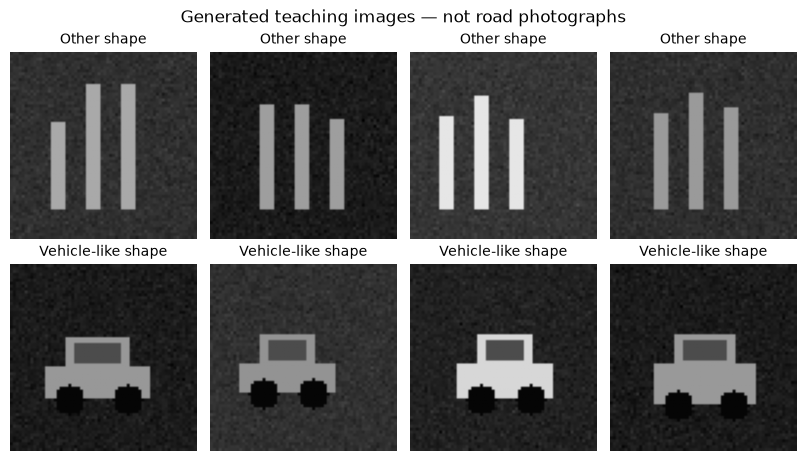

In [3]:
plot_examples(result)
plt.show()

## 3. Convert each image into HOG features

HOG means **Histogram of Oriented Gradients**. Its three steps in `features.py`:

1. Compute horizontal and vertical gradients, then magnitude and direction.
2. In each 8 × 8 pixel cell, accumulate magnitude-weighted votes in nine
   unsigned orientation bins covering 0–180 degrees.
3. Normalize overlapping 2 × 2-cell blocks, clip entries at 0.2, and normalize
   again (L2-Hys). Blocks advance by one cell.

A 64 × 64 image has 8 × 8 cells and 7 × 7 blocks. Its feature vector contains
**7 × 7 × 4 × 9 = 1,764 values**. This compact variant interpolates votes
between orientation bins, but not neighboring spatial cells.

The middle panel below shows gradient magnitude; the right panel shows the
flattened HOG descriptor used as model input.

Feature matrix: **(200, 1764)** (images × features).

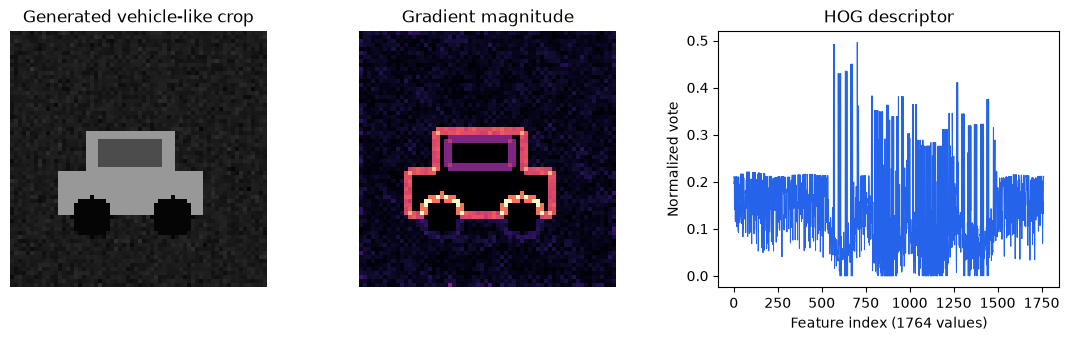

In [4]:
display(Markdown(f"Feature matrix: **{result['features'].shape}** (images × features)."))
plot_features(result)
plt.show()

## 4. Compare two kernels with scikit-learn

A kernel specifies how feature vectors are compared:

| Kernel | Formula | Settings |
| --- | --- | --- |
| Linear | $K(x,z)=x^Tz$ | $C=1$ |
| Gaussian / RBF | $K(x,z)=\exp(-\gamma\|x-z\|^2)$ | $C=1$, $\gamma=0.125$ |

In the Gaussian notation with $\sigma$, $\gamma=1/(2\sigma^2)$, so our RBF
setting corresponds to $\sigma=2$. Both models receive identical training
rows and use a stopping tolerance of `1e-6`. Fitting and prediction use the
library's API:

```python
from sklearn.svm import SVC

model = SVC(kernel="rbf", C=1, gamma=0.125, tol=1e-6)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
```

The shared experiment has already made these calls for both kernels. SVC
uses LIBSVM internally. We record its fit status (`0` means success) and
iteration count. This is library-reported status, not an independent
optimality check. Iteration counts alone do not rank predictive performance.

In [5]:
display(result["metrics"].round(4))
display(pd.DataFrame(result["metadata"]["fits"]))

,method,train_accuracy,test_accuracy,test_f1,support_vectors
0,SVC linear,1.0,1.0,1.0,23
1,SVC rbf,1.0,1.0,1.0,105


,kernel,fit_status,iterations
0,linear,0,122
1,rbf,0,380


## 5. Interpret held-out predictions and support vectors

The confusion matrices have actual classes on rows and predictions on columns.
F1 treats the vehicle-like class (+1) as positive. Support vectors are the
training examples with nonzero coefficients in the decision function:

$$f(x)=\sum_{i\in SV}\alpha_i y_i K(x_i,x)+b.$$

Their contributions determine the separating boundary. `model.predict()`
returns class labels; the decision scores are not probabilities.

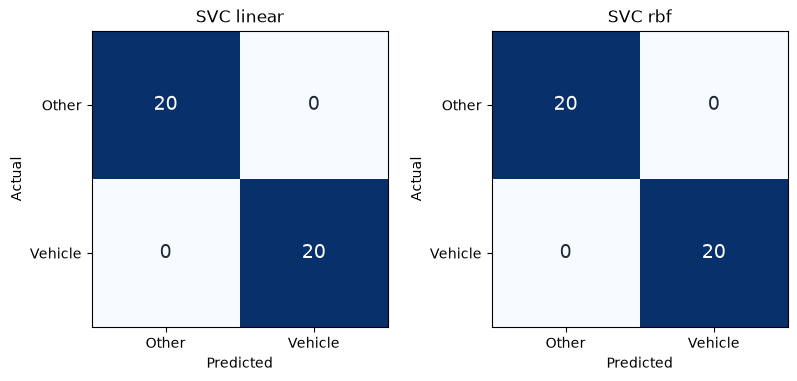

**linear: 40/40** correct test predictions; **23** support vectors.

**rbf: 40/40** correct test predictions; **105** support vectors.

In [6]:
plot_confusion(result)
plt.show()

for kernel in ("linear", "rbf"):
    predicted = result["predictions"][f"SVC {kernel}"]
    correct = int((predicted == result["predictions"]["actual"]).sum())
    support = int(result["models"][kernel].n_support_.sum())
    display(Markdown(f"**{kernel}: {correct}/{len(test)}** correct test predictions; "
                     f"**{support}** support vectors."))

Both kernels classify all 40 generated test images correctly. The RBF model
uses more support vectors, so more examples contribute to each prediction.
These results do not show that RBF is more accurate or that extra flexibility
is always helpful.

Three limits matter:

- **Simple generated data:** the shapes and backgrounds are much easier than
  real photographs. Held-out examples also come from the same generator.
- **Small test set:** broad claims need representative independent data and
  separate validation data for selecting settings.
- **Task and scale:** this classifies individual crops, not vehicle locations
  inside a larger photograph. Kernel SVC training can become costly as the
  sample count grows; this small demonstration does not evaluate that scale.

## 6. Save the reproducible artifacts

The CLI uses the same export function. It writes metrics, test predictions,
run metadata, and three figures: **six files** in total. It does not serialize
the trained models or complete image/feature arrays.

In [7]:
count = save_results(result)
display(Markdown(f"Saved **{count} files** to `svm_vehicle_classification/results/`."))

Saved **6 files** to `svm_vehicle_classification/results/`.

## Optional local crops and sources

To use local images you have permission to process, keep `vehicles/` and
`non-vehicles/` in the Git-ignored data directory, then run from the repo root:

```bash
python -m svm_vehicle_classification.run_experiment --data data/vehicle-crops --per-class 100
```

The loader samples each class, converts to grayscale, resizes to 64 × 64,
and skips exact duplicate normalized images. Encountered duplicates with
conflicting labels raise an error. Related video frames can still cross the
random split; real benchmarks should split by source or sequence.

Local runs export four files to the ignored `work/local-svm-results/` directory:
metrics, predictions, metadata, and confusion matrices. They omit input-image
illustrations and filenames. This public notebook only uses generated images.

- Dalal and Triggs, [Histograms of Oriented Gradients for Human Detection](https://lear.inrialpes.fr/people/triggs/pubs/Dalal-cvpr05.pdf), 2005.
- scikit-learn, [SVC documentation](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html).

The library provides SVM training. The previous handwritten solver and its
optimization outputs have been removed from the current version because its
earlier reference-code permissions were not verified. This does not remove
old Git snapshots. See [implementation history and license scope](../THIRD_PARTY_NOTICES.md#svm-implementation-history).